# Shalaj: pré-temporada e lesões de isquiotibiais

Análise por atleta do suplemento SPSS público. Alvo: pelo menos uma lesão na temporada, não uma janela de sete dias. Consulte o README para protocolo e limitações.

In [1]:
from pathlib import Path
import json
import pandas as pd
import pyreadstat
from IPython.display import display, Markdown, Image
from pipeline import ROOT, FEATURES, download, prepare, run
if not (ROOT / 'results/summary.json').exists():
    run()
summary = json.loads((ROOT / 'results/summary.json').read_text(encoding='utf-8'))
raw, metadata = pyreadstat.read_sav(str(download()))
df = prepare(raw, metadata)
print('Dados originais:', raw.shape, '| Atletas únicos:', raw.player_id.nunique())
print('Ausências:', int(raw.isna().sum().sum()))
print('Códigos do alvo:', metadata.variable_value_labels['total_hamstring_injuries'])
display(df[['player_id', *FEATURES, 'target_hamstring_season']].head())

Dados originais: (143, 49) | Atletas únicos: 143
Ausências: 1
Códigos do alvo: {1.0: 'yes', 2.0: 'no'}


,player_id,age,bmi,previous_hamstring_injury,nordic_failed,hamstring_relative_240_mean,hamstring_asymmetry_60_pct,target_hamstring_season
0,23.0,22.0,23.92,1.0,0,1.602362,0.740242,1
1,63.0,30.0,24.63,1.0,1,1.186107,4.915515,1
2,129.0,31.0,24.86,1.0,1,1.166291,2.731848,1
3,5.0,31.0,24.04,1.0,1,1.373106,1.333333,1
4,9.0,31.0,24.58,0.0,0,1.450969,3.520650,1


## Dicionário e auditoria

Os rótulos SPSS definem o alvo: `1=yes`, `2=no`. Exposição e taxas calculadas ao longo da temporada não são preditores.

In [2]:
dictionary = pd.DataFrame(json.loads((ROOT / 'results/data_dictionary.json').read_text(encoding='utf-8')))
display(dictionary)
print('Excluídas por serem posteriores à avaliação inicial:', summary['excluded_post_baseline'])
print('SHA-256:', summary['sha256'])

,column,label,codes,missing,unique
0,player_id,player id,{},0,143
1,age,age (yrs),{},0,17
2,body_mass,mass (kg),{},0,111
3,bmi,kg/m2,{},0,129
4,body_height,height (cm),{},0,99
5,dominant_leg,dominant leg,"{'1.0': 'right', '2.0': 'left'}",0,2
6,play_position,playing position,"{'1.0': 'keeper', '2.0': 'int defender', '3.0'...",0,7
7,sit_reach,sit & reach (cm),{},0,34
8,nordic_hamstring_test,nordic hamstring test,"{'1.0': 'yes', '2.0': 'no'}",0,2
9,hamstrings_concentric_60_dom,"hamstring strength (conc, 60 deg/s) dominant (Nm)",{},0,131


Excluídas por serem posteriores à avaliação inicial: ['Time_exposure_hours_Training', 'Time_exposure_hours_Match', 'Time_exposure_hours_Training_and_Match', 'Injury_Rate_training', 'Injury_Rate_match', 'Injury_Rate_TOTAL']
SHA-256: b71f6e48a6c0f941a304c616dda57d2c93d003980f8bedb37b0b453087ac974f


## Avaliação interna e associações

Cinco folds externos estratificados; calibração RF em três folds internos. As métricas são OOF. Intervalos bootstrap são condicionais às previsões, sem validação externa.

In [3]:
display(Markdown((ROOT / 'results/RESULTADOS.md').read_text(encoding='utf-8')))
pred = pd.read_csv(ROOT / 'data/processed/oof_predictions.csv')
assert pred.player_id.is_unique and len(pred) == len(raw)
assert pred['fold'].between(0, 4).all()
assert pred[['prevalencia','logistica','rf_sigmoid']].notna().all().all()
print('Verificação: uma previsão OOF por atleta e por modelo.')

# Resultados executados - Shalaj

Atletas: 143; com lesão: 40; prevalência: 27.97%.

| Modelo | ROC-AUC OOF | IC 95% condicional | AP | Brier | Log loss |
|---|---:|---|---:|---:|---:|
| prevalencia | 0.4942 | 0.402–0.582 | 0.2774 | 0.2015 | 0.5927 |
| logistica | 0.8053 | 0.727–0.876 | 0.5442 | 0.1617 | 0.4855 |
| rf_sigmoid | 0.8235 | 0.754–0.890 | 0.6266 | 0.1512 | 0.4600 |

Resultados internos exploratórios. Não são previsões validadas por clube nem risco em sete dias.

## Associações observadas

| Variável | Spearman | Média sem lesão | Média com lesão |
|---|---:|---:|---:|
| age | +0.474 | 22.146 | 26.050 |
| bmi | +0.250 | 22.626 | 23.629 |
| previous_hamstring_injury | +0.191 | 0.233 | 0.425 |
| nordic_failed | +0.286 | 0.291 | 0.600 |
| hamstring_relative_240_mean | -0.069 | 1.357 | 1.332 |
| hamstring_asymmetry_60_pct | -0.065 | 9.873 | 8.164 |


Verificação: uma previsão OOF por atleta e por modelo.


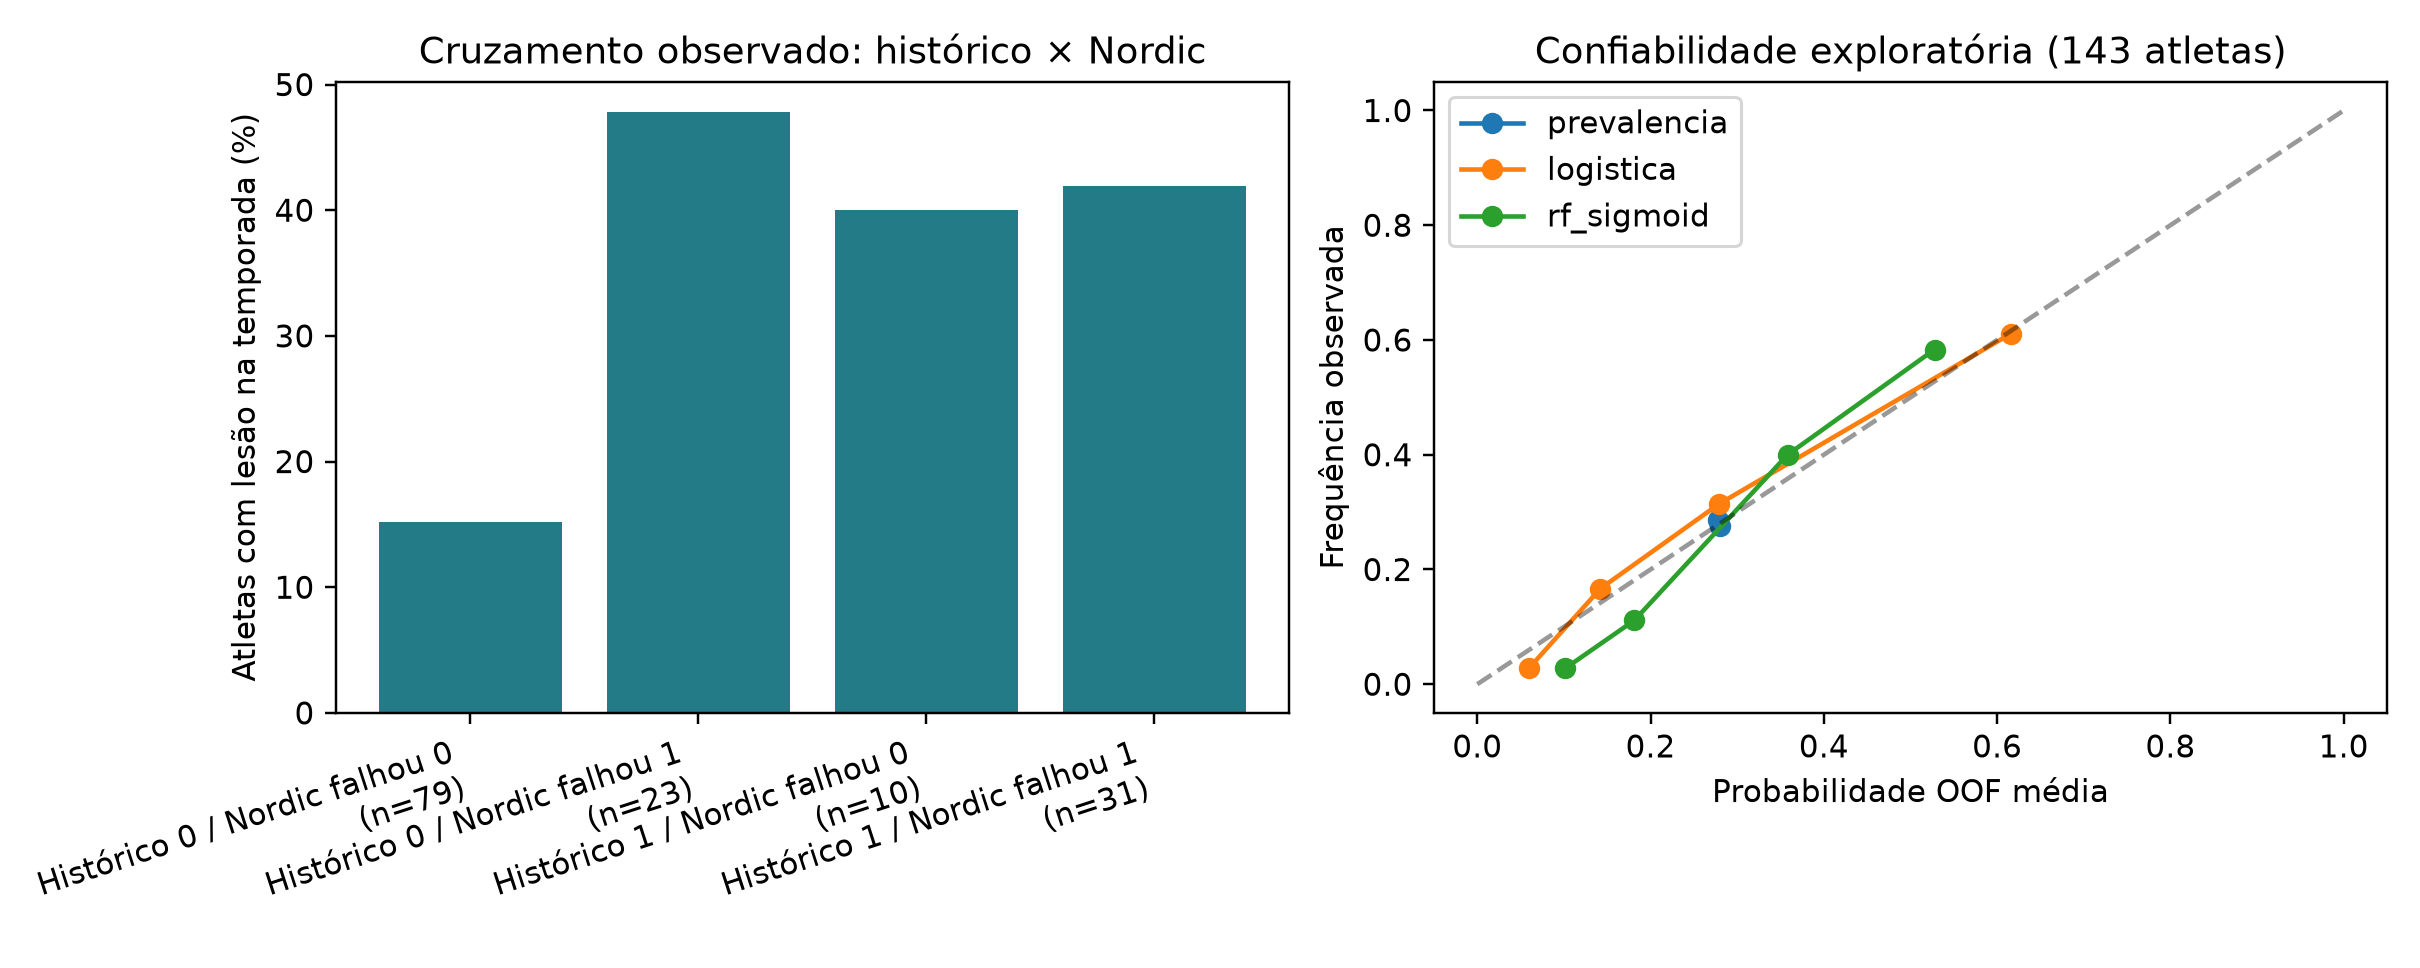

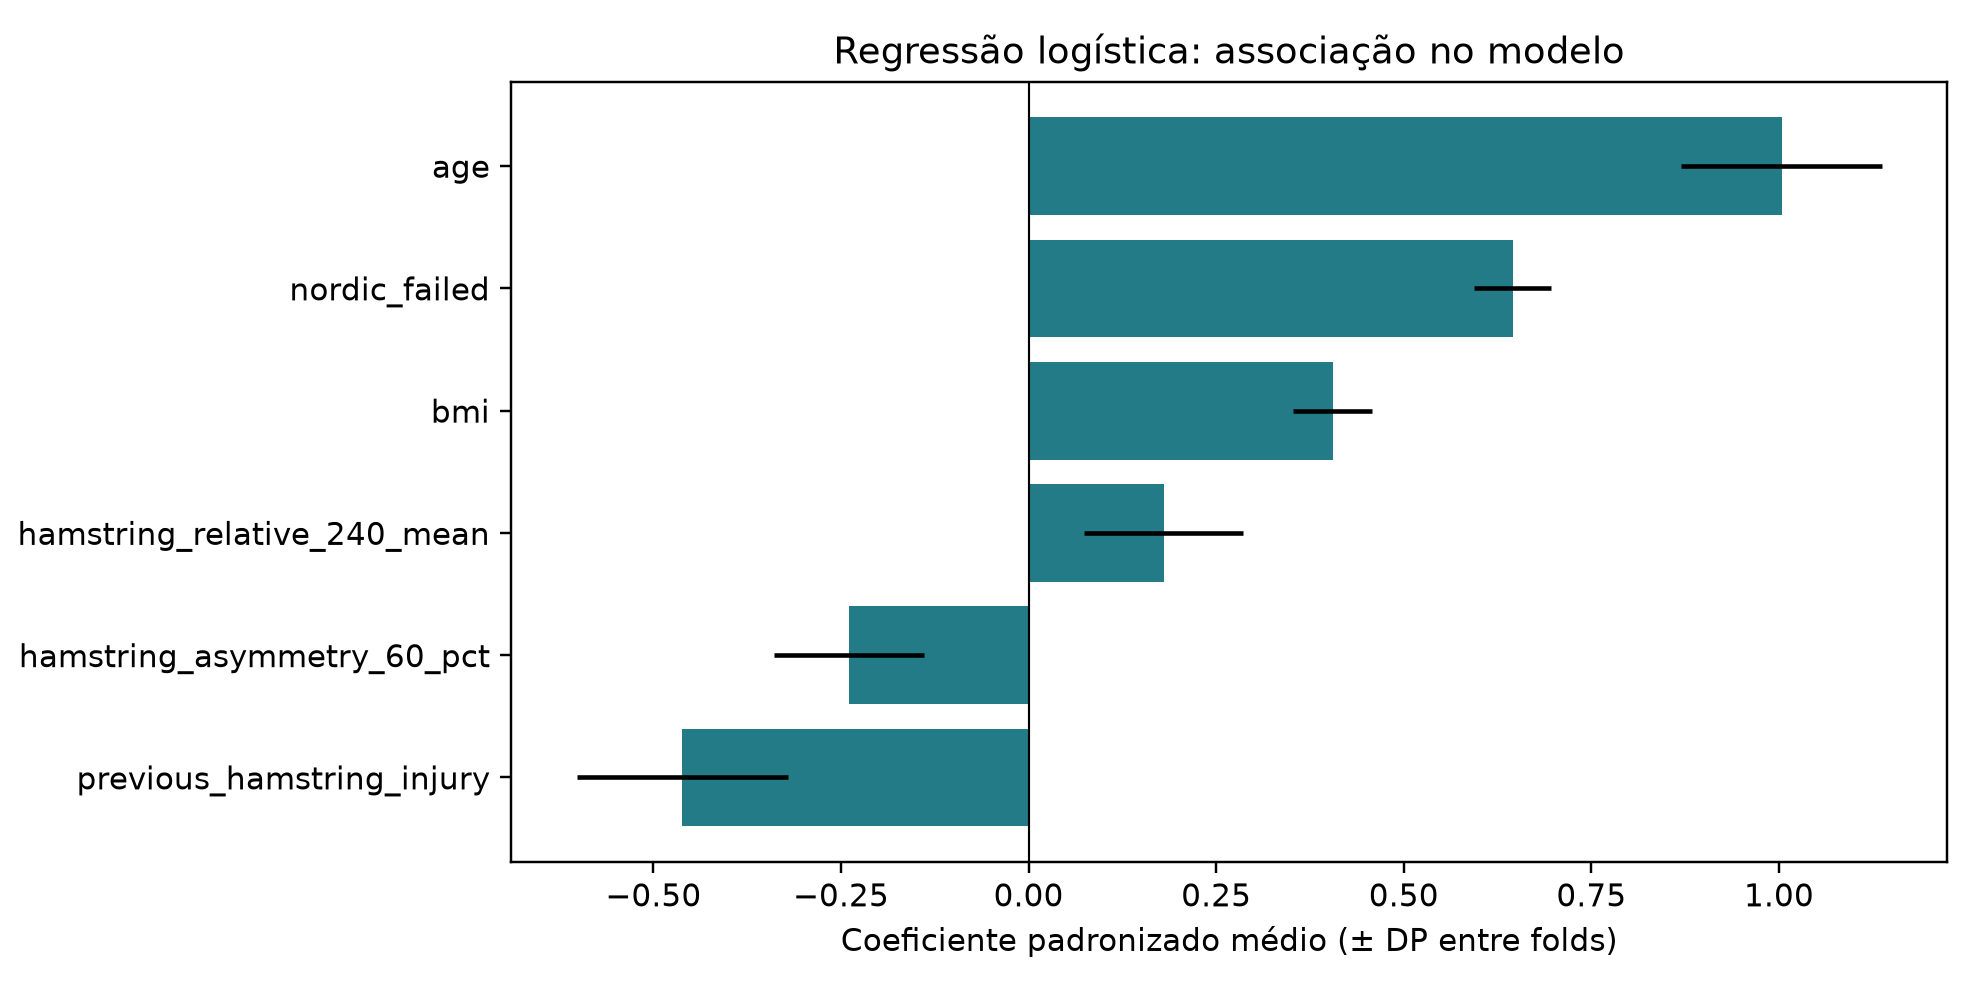

In [4]:
display(Image(filename=str(ROOT / 'figures/cruzamento_e_calibracao.png')))
display(Image(filename=str(ROOT / 'figures/coeficientes_logistica.png')))

## Limites

143 atletas; 40 atletas positivos, distintos dos 43 episódios relatados no artigo. Sem identificador de clube nem datas dos episódios. Não se combinam participantes com outras bases. Ausência de sono e carga diária impede testar a interação carga × recuperação. Para recalcular tudo: `python shalaj/pipeline.py` na raiz do projeto.